(2026-08-31) :: Estimated number of worms: 1 out of 2325 total frames


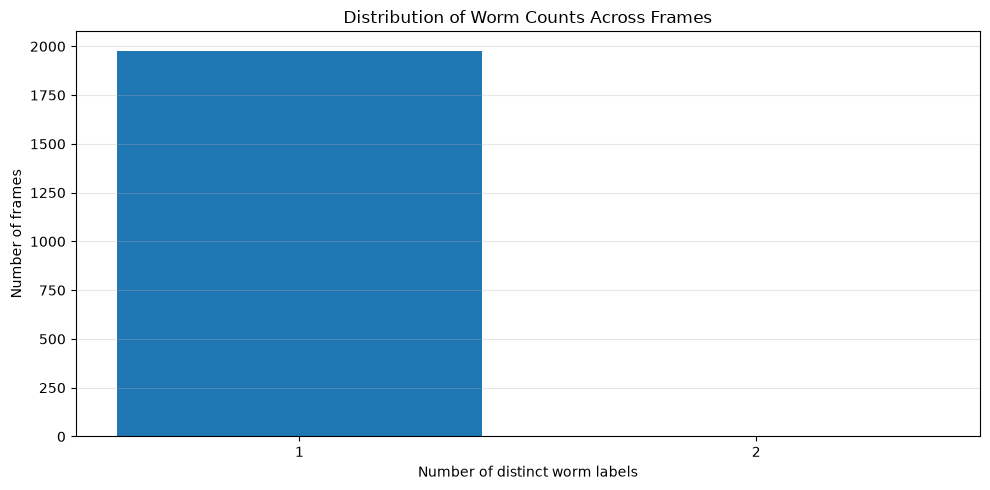

(2026-09-18) :: Estimated number of worms: 1 out of 2189 total frames


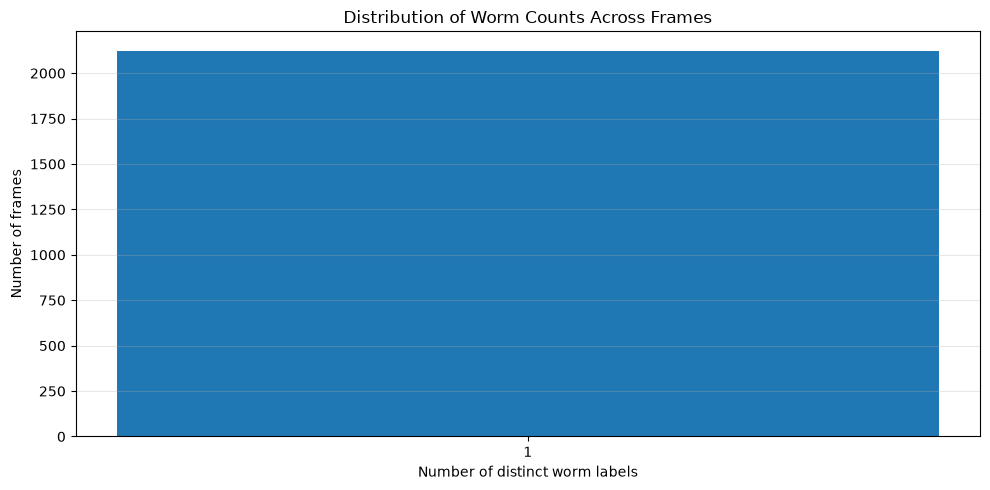

(2026-09-15) :: Estimated number of worms: 1 out of 21294 total frames


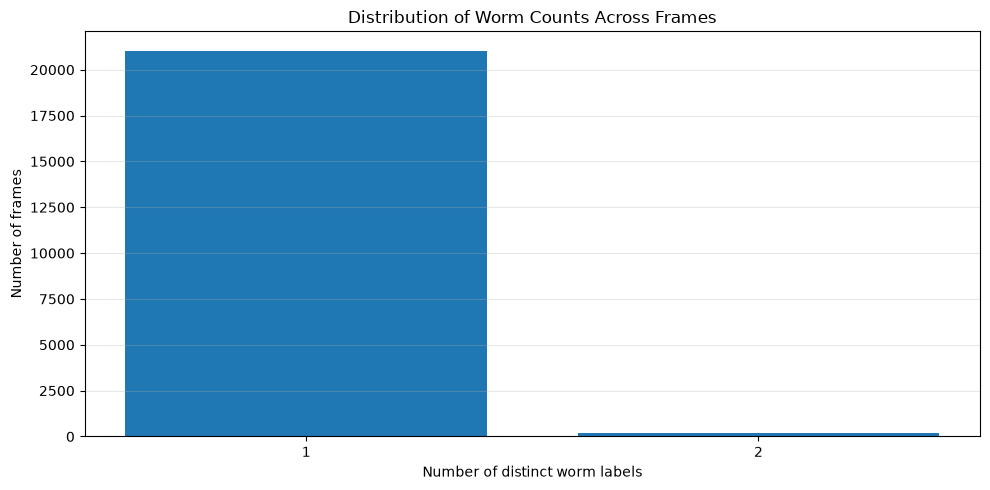

(2026-09-22) :: Estimated number of worms: 1 out of 162 total frames


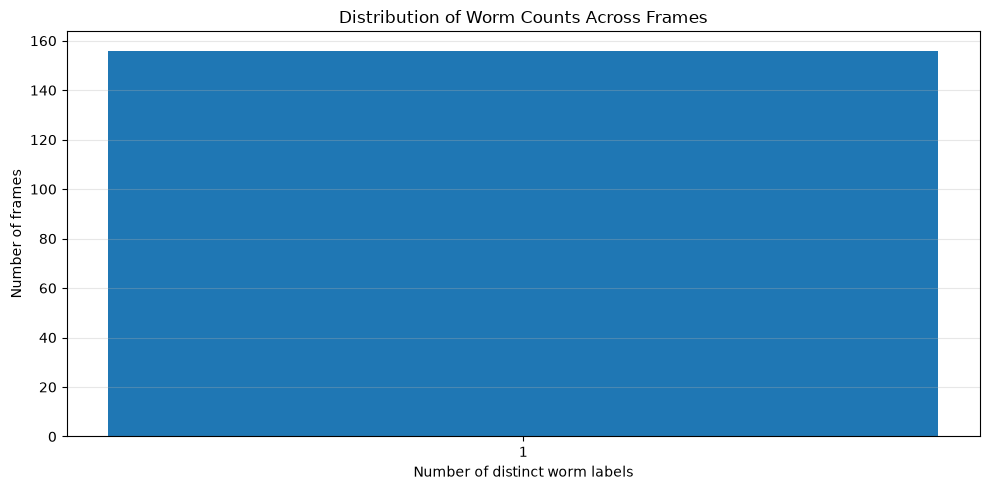

(2026-06-26) :: Estimated number of worms: 1 out of 3995 total frames


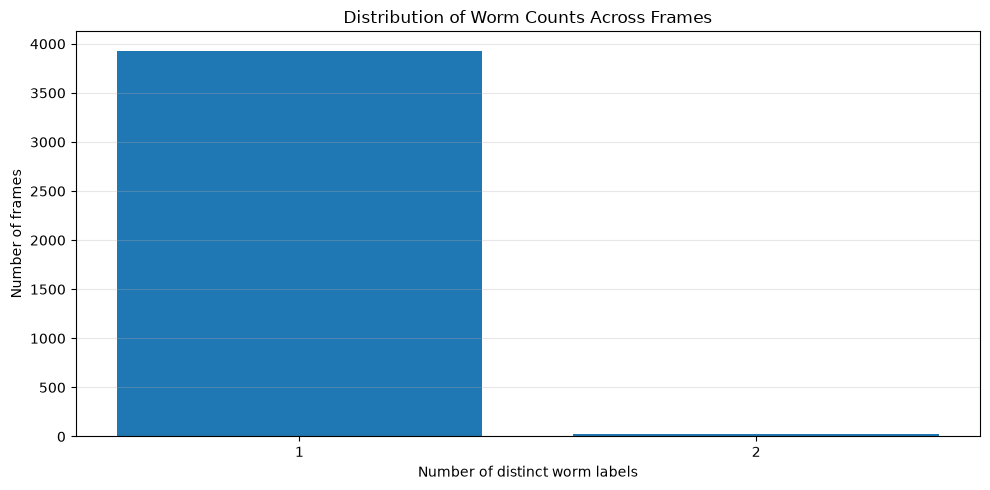

(2026-09-18) :: Estimated number of worms: 1 out of 5505 total frames


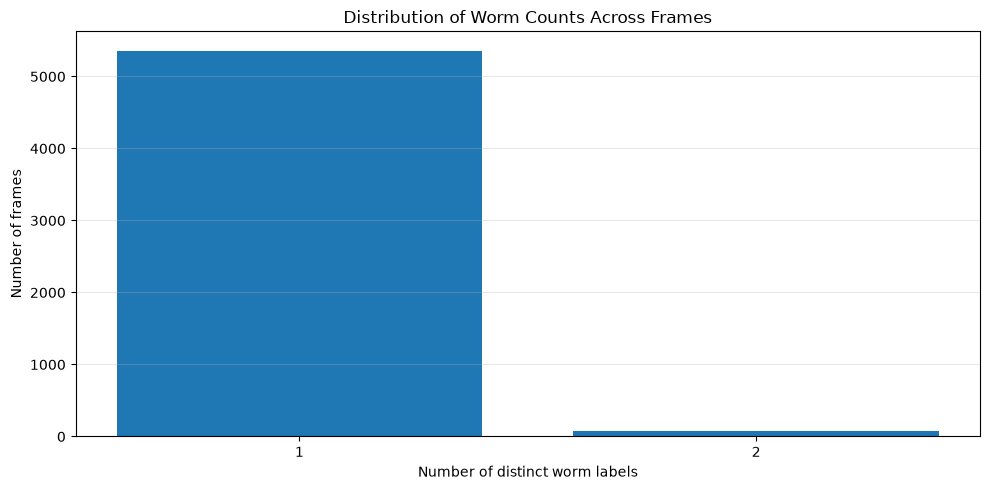

(2026-09-16) :: Estimated number of worms: 1 out of 2649 total frames


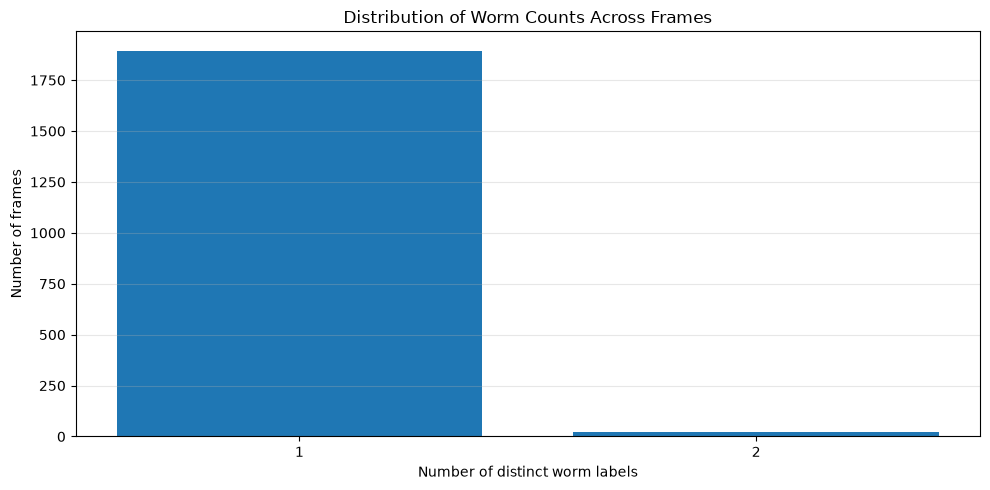

(2026-09-17) :: Estimated number of worms: 2 out of 18630 total frames


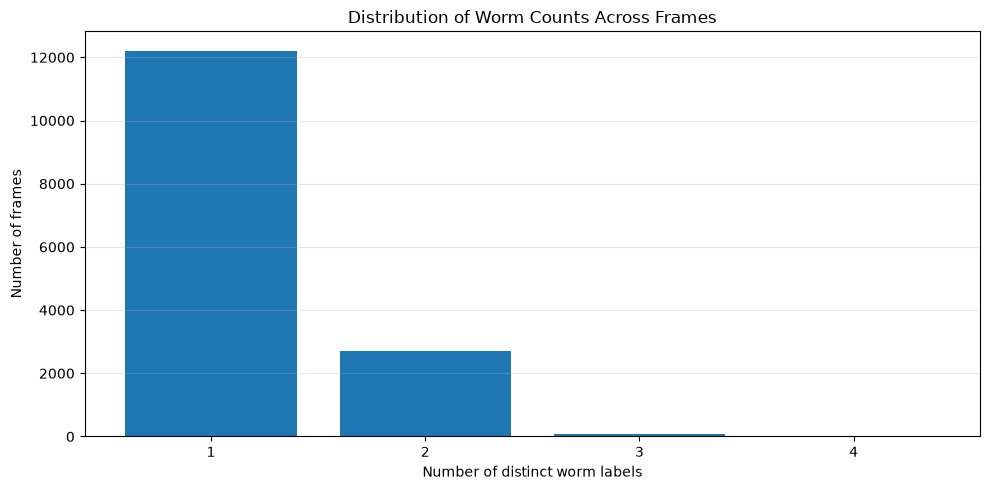

In [4]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from search_data import *

def estimate_worm_count(hdf5_path, window_size=100):
    with h5py.File(hdf5_path, "r") as f:
        data = f["/trajectories_data"][:]

    frames = data["frame_number"]
    labels = data["worm_index_joined"]

    total_frames = len(np.unique(frames))

    # Filter invalid labels.
    valid = labels > 0

    # Filter poor skeletons when these fields are available.
    if "has_skeleton" in data.dtype.names:
        valid &= data["has_skeleton"] == 1

    if "is_good_skel" in data.dtype.names:
        valid &= data["is_good_skel"] == 1

    frames = frames[valid]
    labels = labels[valid]

    if len(frames) == 0:
        return None, {}

    # Count distinct valid worm labels per frame.
    frame_counts = {}

    for frame in np.unique(frames):
        frame_labels = labels[frames == frame]
        frame_counts[frame] = len(np.unique(frame_labels))

    # Convert counts to a chronological sequence.
    ordered_frames = np.array(sorted(frame_counts))
    counts = np.array([frame_counts[f] for f in ordered_frames])

    if len(counts) < window_size:
        # Not enough frames for the requested window.
        return int(np.max(counts)), frame_counts

    # Calculate the rolling average count.
    rolling_means = np.convolve(
        counts,
        np.ones(window_size) / window_size,
        mode="valid"
    )

    # Find the window with the highest average count.
    best_window = np.argmax(rolling_means)

    # Estimate the population from the most frequent count
    # within that window.
    window_counts = counts[
        best_window:best_window + window_size
    ]

    estimated_count = Counter(window_counts).most_common(1)[0][0]

    return int(estimated_count), frame_counts, total_frames


def plot_worm_count_distribution(frame_counts):
    """
    Plot the frequency of each worm count across frames.

    Args:
        frame_counts: Dictionary mapping frame numbers to worm counts.
    """
    count_frequency = Counter(frame_counts.values())

    worm_counts = sorted(count_frequency)
    frequencies = [count_frequency[n] for n in worm_counts]

    plt.figure(figsize=(10, 5))
    plt.bar(worm_counts, frequencies)

    plt.xlabel("Number of distinct worm labels")
    plt.ylabel("Number of frames")
    plt.title("Distribution of Worm Counts Across Frames")
    plt.xticks(worm_counts)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

def analyze_video_directory(video_dir):
    vid_date = str(video_dir).removeprefix(VIDEO_DATA_BASE_DIR_STR + "/")[:10]
    all_outputs = get_all_output_paths(video_dir)

    estimated_count, frame_counts, total_frames = estimate_worm_count(all_outputs['skeletons'], window_size=100)
    print(f"({vid_date}) :: Estimated number of worms: {estimated_count} out of {total_frames} total frames")
    plot_worm_count_distribution(frame_counts)
    pass

for vid_dir in video_directories:
    analyze_video_directory(vid_dir)

In [ ]:
def find_first_fully_labeled_frame(hdf5_path, expected_worms):
    with h5py.File(hdf5_path, "r") as f:
        trajectories = f["/trajectories_data"][:]

    frames = trajectories["frame_number"]
    labels = trajectories["worm_index_joined"]

    for frame in np.unique(frames):
        frame_labels = labels[frames == frame]

        valid_labels = frame_labels[frame_labels > 0]

        if (
            len(valid_labels) == len(frame_labels)
            and len(np.unique(valid_labels)) == expected_worms
        ):
            return frame

    return None